In [1]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv('Dataset/onlyPoliticsAutoScraping.csv', index_col=False)

df = df.reset_index(drop=True)
df

,url,title,text,authors,domain,score,country,language,topics,paywall,opinion_advocacy,label
0,https://nemontananews.com/stories/670532029-1-...,1 gas station in cities throughout Phillips Co...,Federal Energy Regulatory Commission (FERC) Ch...,Northeast Montana News,nemontananews.com,32.0,US,en,Political news or commentary,No,Yes,0
1,https://nemontananews.com/stories/670175501-mc...,McCone County: Income Maintenance dependency r...,"John Lettieri, President and CEO of Economic I...",Northeast Montana News,nemontananews.com,32.0,US,en,Political news or commentary,No,Yes,0
2,https://nemontananews.com/stories/670489322-da...,"Daniels County residents received $13,488 per ...","John Lettieri, President and CEO of Economic I...",Northeast Montana News,nemontananews.com,32.0,US,en,Political news or commentary,No,Yes,0
3,https://nemontananews.com/stories/670175454-da...,Daniels County: Income Maintenance made up 0.8...,"John Lettieri, President and CEO of Economic I...",Northeast Montana News,nemontananews.com,32.0,US,en,Political news or commentary,No,Yes,0
4,https://nemontananews.com/stories/670413125-wh...,Where could drivers find the cheapest gas in c...,Federal Energy Regulatory Commission (FERC) Co...,Northeast Montana News,nemontananews.com,32.0,US,en,Political news or commentary,No,Yes,0
...,...,...,...,...,...,...,...,...,...,...,...,...
26904,https://petroplexnews.com/stories/670531458-1-...,1 gas station in cities throughout Winkler Cou...,Federal Energy Regulatory Commission (FERC) Co...,Petroplex News,petroplexnews.com,32.0,US,en,Political news or commentary,No,Yes,0
26905,https://petroplexnews.com/stories/670540703-wh...,Where were the cheapest places to fill up on m...,Federal Energy Regulatory Commission (FERC) Co...,Petroplex News,petroplexnews.com,32.0,US,en,Political news or commentary,No,Yes,0
26906,https://www.nerdwallet.com/article/credit-card...,Can Gas Stations Charge More for Using a Credi...,"Whenever gas prices rise, you tend to look for...",About The Authors,petroplexnews.com,32.0,US,en,Political news or commentary,No,Yes,0
26907,https://petroplexnews.com/stories/670172452-wi...,Winkler County: Income Maintenance dependency ...,"John Lettieri, President and CEO of Economic I...",Petroplex News,petroplexnews.com,32.0,US,en,Political news or commentary,No,Yes,0


## Remove duplicates

In [2]:
# Controlla se ci sono duplicati per ciascuna colonna
print("Duplicati per URL:", df['url'].duplicated().sum())
print("Duplicati per Text:", df['text'].duplicated().sum())


Duplicati per URL: 1137
Duplicati per Text: 2250


In [3]:
# Rimuove i duplicati basandosi su url o text
df_cleaned = df.drop_duplicates(subset=['url', 'text'], keep='first')

# Mostra il risultato
print("Dimensione originale:", len(df))
print("Dimensione dopo rimozione duplicati:", len(df_cleaned))
print("Duplicati rimossi:", len(df) - len(df_cleaned))



df = df_cleaned

Dimensione originale: 26909
Dimensione dopo rimozione duplicati: 25822
Duplicati rimossi: 1087


# Define the function to plot

In [4]:
def plot_label_analysis(df, figsize=(10, 15), save_path=None):
    """
    Creates three analysis plots for label distribution and domain relationships
    
    Parameters:
    df (pd.DataFrame): Input dataframe containing 'label' and 'domain' columns
    figsize (tuple): Figure size (width, height)
    save_path (str): Optional path to save the figure
    """
    plt.figure(figsize=figsize)
    
    # Create subplots grid
    fig, ax = plt.subplots(3, 1, figsize=figsize)
    
    # Plot 1: Distinct domains per label
    distinct_domains = df.groupby("label")["domain"].nunique()
    distinct_domains.plot(kind="bar", color="skyblue", edgecolor="black", ax=ax[0])
    ax[0].set_title("Distinct Domains per Label")
    ax[0].set_ylabel("Number of Distinct Domains")
    ax[0].grid(axis="y", linestyle="--", alpha=0.7)
    
    # Plot 2: Number of articles per label
    articles_per_label = df["label"].value_counts().sort_index()
    articles_per_label.plot(kind="bar", color="lightcoral", edgecolor="black", ax=ax[1])
    ax[1].set_title("Number of Articles per Label")
    ax[1].set_ylabel("Number of Articles")
    ax[1].grid(axis="y", linestyle="--", alpha=0.7)
    
    # Plot 3: Average articles per domain per label
    articles_per_domain = df.groupby(["label", "domain"]).size().reset_index(name="article_count")
    avg_articles = articles_per_domain.groupby("label")["article_count"].mean()
    avg_articles.plot(kind="bar", color="mediumseagreen", edgecolor="black", ax=ax[2])
    ax[2].set_title("Average Articles per Domain per Label")
    ax[2].set_ylabel("Average Articles per Domain")
    ax[2].grid(axis="y", linestyle="--", alpha=0.7)
    
    # Common formatting
    for axis in ax:
        axis.set_xlabel("Label")
        axis.set_xticklabels(axis.get_xticklabels(), rotation=0)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, bbox_inches="tight")
    plt.show()

<Figure size 1000x1500 with 0 Axes>

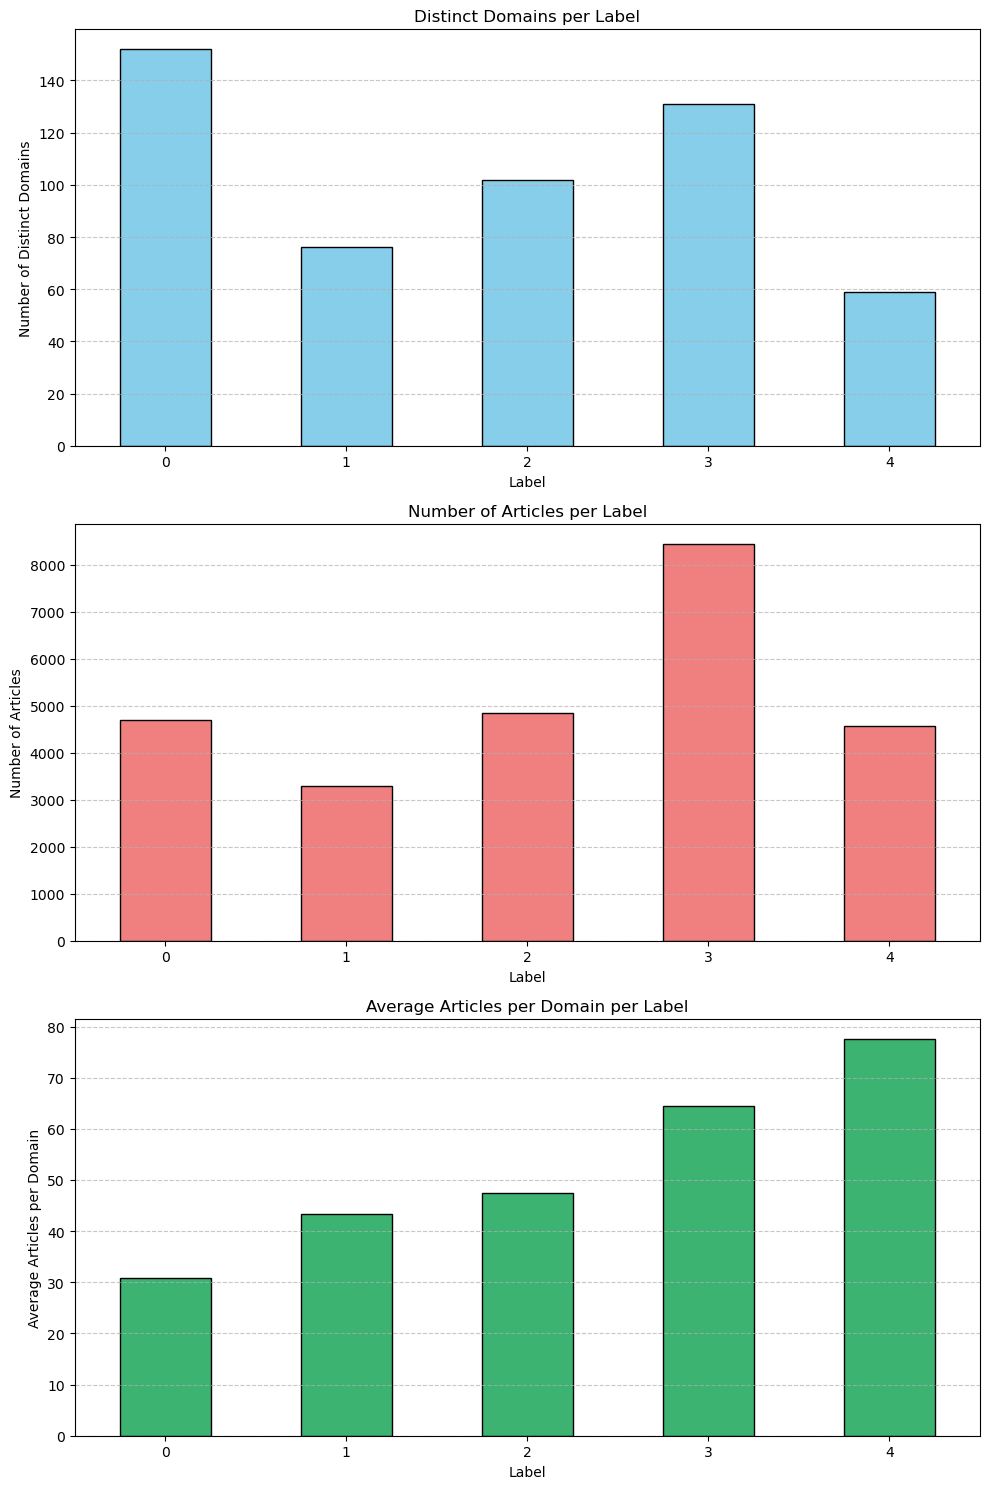

In [5]:
plot_label_analysis(df) 


# Deleting non english articles

In [6]:
from langdetect import detect, LangDetectException
from tqdm import tqdm
# Set a seed for deterministic results
from langdetect import DetectorFactory
DetectorFactory.seed = 0
# Install required packages if needed
# !pip install langdetect tqdm

# Initialize tqdm for pandas
tqdm.pandas()

def is_english(text):
    try:
        if pd.notna(text) and isinstance(text, str) and len(text.strip()) > 0:
            return detect(text) == 'en'
        return False
    except LangDetectException:
        return False

# Store original count
original_rows = len(df)

# Create progress bar while checking language
df['is_english'] = df['text'].progress_apply(is_english)

# Filter DataFrame
df_filtered = df[df['is_english']].copy()

# Calculate removal stats
removed_rows = original_rows - len(df_filtered)
remaining_rows = len(df_filtered)

print(f"\nRemoved {removed_rows} non-English articles")
print(f"Final dataset contains {remaining_rows} English articles")

# Optional: Drop the temporary column
df_filtered = df_filtered.drop(columns=['is_english'])

# Assign back to original DataFrame if needed
df = df_filtered

100%|████████████████████████████████████| 25822/25822 [02:46<00:00, 155.35it/s]


Removed 7401 non-English articles
Final dataset contains 18421 English articles



/tmp/ipykernel_2602465/4112196455.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['is_english'] = df['text'].progress_apply(is_english)


In [7]:
df = df.reset_index(drop=True)

In [8]:
df.to_csv('Dataset/Temp/onlyPoliticsAutoScrapingOnlyEnglish.csv', index=False)

### Checkpoint

In [9]:
df = pd.read_csv('Dataset/Temp/onlyPoliticsAutoScrapingOnlyEnglish.csv', index_col=False)

df = df.reset_index(drop=True)

# Drop columns that start with "Unnamed"
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]


<Figure size 1000x1500 with 0 Axes>

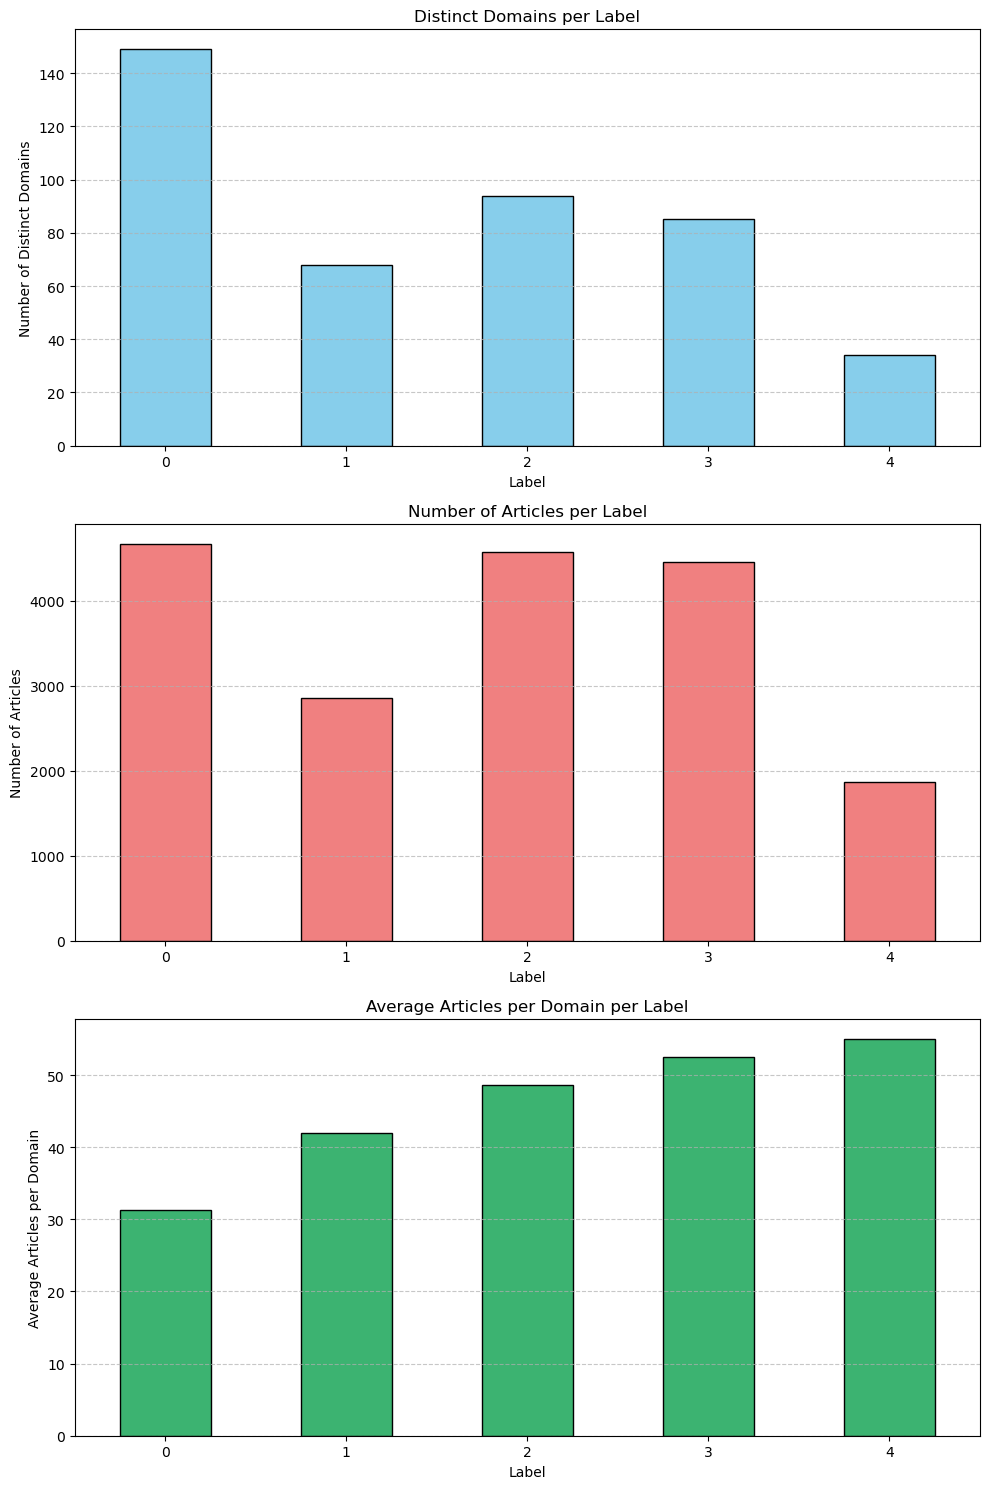

In [10]:
plot_label_analysis(df) 

# Import the old dataframe (paper one)

In [11]:
paperDf = pd.read_csv('Dataset/articoli_originali.csv', sep="§", engine='python', encoding='utf8')

# Binning the score column value in the old dataframe (paper one)

In [12]:
# Now, you can convert the 'Score' column to integers
paperDf["label"] = paperDf["Score"].astype(int)


# Definizione delle fasce
bins = [-1, 39, 59, 74, 99, 100]  
labels = [0, 1, 2, 3, 4]

# Trasformazione dei valori della colonna "label"
paperDf['label'] = pd.cut(paperDf['label'], bins=bins, labels=labels)

# Reset index
paperDf = paperDf.reset_index(drop=True)

In [13]:
paperDf

,url,domain_x,label_x,title_x,text_x,ng_topic_x,Score,label
0,https://www.12up.com/posts/jeff-samardzija-lig...,12up.com,newspaper,Jeff Samardzija Lights Fire Under Owners in Sa...,"The San Francisco Giants, along with all 29 ot...",Sports and athletics,95.0,3
1,https://www.12up.com/posts/blue-jays-throw-col...,12up.com,newspaper,Blue Jays Throw Cold Water on Nate Pearson Ban...,The Toronto Blue Jays have a potential star in...,Sports and athletics,95.0,3
2,https://www.12up.com/posts/collin-mchugh-right...,12up.com,newspaper,Collin McHugh Rightfully Flames MLB Owners Ove...,While the 2020 MLB season is set to commence l...,Sports and athletics,95.0,3
3,https://www.12up.com/posts/celebrating-35th-an...,12up.com,newspaper,Celebrating the 35th Anniversary of the Certif...,The New York Mets and Atlanta Braves have alwa...,Sports and athletics,95.0,3
4,https://www.12up.com/posts/theo-epstein-commen...,12up.com,newspaper,Theo Epstein Commends Cubs Pitching Coach Tomm...,"For reasons we'll never understand, certain in...",Sports and athletics,95.0,3
...,...,...,...,...,...,...,...,...
4028,https://drjockers.com/3-powerful-foods-reducin...,drjockers.com,newspaper,3 Powerful Foods That Reduce Inflammation,Powerful foods can be extraordinary for your o...,Health or medical information,20.0,0
4029,https://drjockers.com/music-therapy/,drjockers.com,newspaper,3 Ways Music Therapy Improves Brain Function,Music therapy improves brain health in a numbe...,Health or medical information,20.0,0
4030,https://drjockers.com/brain-boosting-supplements/,drjockers.com,newspaper,Top 10 Brain Boosting Supplements,This article goes over the top 10 brain boos...,Health or medical information,20.0,0
4031,https://drjockers.com/peppermint/,drjockers.com,newspaper,5 Ways Peppermint Can Be Used As Medicine,Peppermint is a superfood herb that has been u...,Health or medical information,20.0,0


# Keeping just the poitics rows from the old dataframe

In [14]:


paperDfOnlyPolitics = paperDf[paperDf['ng_topic_x'] == 'Political_news_or_commentary']
paperDfOnlyPolitics = paperDfOnlyPolitics.reset_index(drop=True)

In [15]:
paperDfOnlyPolitics.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1055 entries, 0 to 1054
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   url         1055 non-null   object  
 1   domain_x    1055 non-null   object  
 2   label_x     1055 non-null   object  
 3   title_x     1055 non-null   object  
 4   text_x      1055 non-null   object  
 5   ng_topic_x  1055 non-null   object  
 6   Score       1055 non-null   float64 
 7   label       1055 non-null   category
dtypes: category(1), float64(1), object(6)
memory usage: 59.1+ KB


# Merging the old with the new just politics

## Edit the columns of the paper dataframe

In [16]:
# Step 1: Align column names between both DataFrames
column_mapping = {
    'domain_x': 'domain',
    'title_x': 'title',
    'text_x': 'text',
    'ng_topic_x': 'topics',
    'Score': 'score',
    'label': 'label'  # Keep whichever label column is appropriate
}

# Rename columns in the new DataFrame
paperDfOnlyPolitics = paperDfOnlyPolitics.rename(columns=column_mapping)

# Removing unused column
paperDfOnlyPolitics.drop('label_x', axis=1, inplace=True)


paperDfOnlyPolitics

,url,domain,title,text,topics,score,label
0,https://www.aclu.org/news/free-speech/the-snea...,aclu.org,The Sneaky Way the Police Could Abuse Their Po...,"In 2019, police in Castle Hills, Texas arreste...",Political_news_or_commentary,92.5,3
1,https://www.aclu.org/news/criminal-law-reform/...,aclu.org,911: Reimagining a System that Defaults to Dis...,"Every person deserves equal, effective treatme...",Political_news_or_commentary,92.5,3
2,https://www.aclu.org/news/free-speech/when-com...,aclu.org,When Complaining About a Public Official Can L...,This piece was published in partnership with T...,Political_news_or_commentary,92.5,3
3,https://www.aclu.org/podcast/why-and-how-trans...,aclu.org,Why and How Trans Hate is Spreading,The ACLU is tracking 452 anti-LGBTQ bills in t...,Political_news_or_commentary,92.5,3
4,https://www.aclu.org/news/racial-justice/natio...,aclu.org,National Crisis in Policing Awaits United Nati...,"In May 2020, a Minneapolis police officer knee...",Political_news_or_commentary,92.5,3
...,...,...,...,...,...,...,...
1050,https://www.truthdig.com/articles/us-house-vot...,truthdig.com,US House Vote Rolls Back Wetlands Regulations,The U.S. House voted Thursday to undo a Biden ...,Political_news_or_commentary,80.0,3
1051,https://www.truthdig.com/articles/environmenta...,truthdig.com,Environmental Racism in Canada,Informed nine months after the fact that its h...,Political_news_or_commentary,80.0,3
1052,https://www.truthdig.com/articles/the-runaway-...,truthdig.com,The Runaway Train of Corporate Greed,Thursday’s U.S. Senate hearing about the ongoi...,Political_news_or_commentary,80.0,3
1053,https://www.truthdig.com/articles/ron-desantis...,truthdig.com,Ron DeSantis’ Phantom War Against Voter Fraud,A new Florida law gives Gov.Ron DeSantis’ pros...,Political_news_or_commentary,80.0,3


## Perform the merging

In [17]:
import pandas as pd

# Print the number of rows before merging
print(f"Number of rows in df before merge: {len(df)}")
print(f"Number of rows in paperDfOnlyPolitics: {len(paperDfOnlyPolitics)}")

# Identify common columns
df_columns = set(df.columns)
paper_columns = set(paperDfOnlyPolitics.columns)

# Find missing columns in paperDfOnlyPolitics and add them as None
missing_columns = df_columns - paper_columns
for col in missing_columns:
    paperDfOnlyPolitics[col] = None

# Ensure column order matches df
paperDfOnlyPolitics = paperDfOnlyPolitics[df.columns]

# Remove duplicates based on the 'url' column
existing_urls = set(df["url"])
new_rows = paperDfOnlyPolitics[~paperDfOnlyPolitics["url"].isin(existing_urls)]
duplicate_rows = paperDfOnlyPolitics[paperDfOnlyPolitics["url"].isin(existing_urls)]

# Print duplicates
if duplicate_rows.empty:
    print("\nNo duplicate articles found. All new articles will be added.")
else:
    print("\nArticles already present in df and not added:")
    print(duplicate_rows[["url", "title"]])

# Concatenate only new rows
df = pd.concat([df, new_rows], ignore_index=True)

# Print the number of rows after merging
print(f"\nNumber of rows in df after merge: {len(df)}")


Number of rows in df before merge: 18421
Number of rows in paperDfOnlyPolitics: 1055

No duplicate articles found. All new articles will be added.

Number of rows in df after merge: 19476


In [18]:
df

,url,title,text,authors,domain,score,country,language,topics,paywall,opinion_advocacy,label
0,https://nemontananews.com/stories/670532029-1-...,1 gas station in cities throughout Phillips Co...,Federal Energy Regulatory Commission (FERC) Ch...,Northeast Montana News,nemontananews.com,32.0,US,en,Political news or commentary,No,Yes,0
1,https://nemontananews.com/stories/670175501-mc...,McCone County: Income Maintenance dependency r...,"John Lettieri, President and CEO of Economic I...",Northeast Montana News,nemontananews.com,32.0,US,en,Political news or commentary,No,Yes,0
2,https://nemontananews.com/stories/670489322-da...,"Daniels County residents received $13,488 per ...","John Lettieri, President and CEO of Economic I...",Northeast Montana News,nemontananews.com,32.0,US,en,Political news or commentary,No,Yes,0
3,https://nemontananews.com/stories/670175454-da...,Daniels County: Income Maintenance made up 0.8...,"John Lettieri, President and CEO of Economic I...",Northeast Montana News,nemontananews.com,32.0,US,en,Political news or commentary,No,Yes,0
4,https://nemontananews.com/stories/670413125-wh...,Where could drivers find the cheapest gas in c...,Federal Energy Regulatory Commission (FERC) Co...,Northeast Montana News,nemontananews.com,32.0,US,en,Political news or commentary,No,Yes,0
...,...,...,...,...,...,...,...,...,...,...,...,...
19471,https://www.truthdig.com/articles/us-house-vot...,US House Vote Rolls Back Wetlands Regulations,The U.S. House voted Thursday to undo a Biden ...,None,truthdig.com,80.0,None,None,Political_news_or_commentary,None,None,3
19472,https://www.truthdig.com/articles/environmenta...,Environmental Racism in Canada,Informed nine months after the fact that its h...,None,truthdig.com,80.0,None,None,Political_news_or_commentary,None,None,3
19473,https://www.truthdig.com/articles/the-runaway-...,The Runaway Train of Corporate Greed,Thursday’s U.S. Senate hearing about the ongoi...,None,truthdig.com,80.0,None,None,Political_news_or_commentary,None,None,3
19474,https://www.truthdig.com/articles/ron-desantis...,Ron DeSantis’ Phantom War Against Voter Fraud,A new Florida law gives Gov.Ron DeSantis’ pros...,None,truthdig.com,80.0,None,None,Political_news_or_commentary,None,None,3


<Figure size 1000x1500 with 0 Axes>

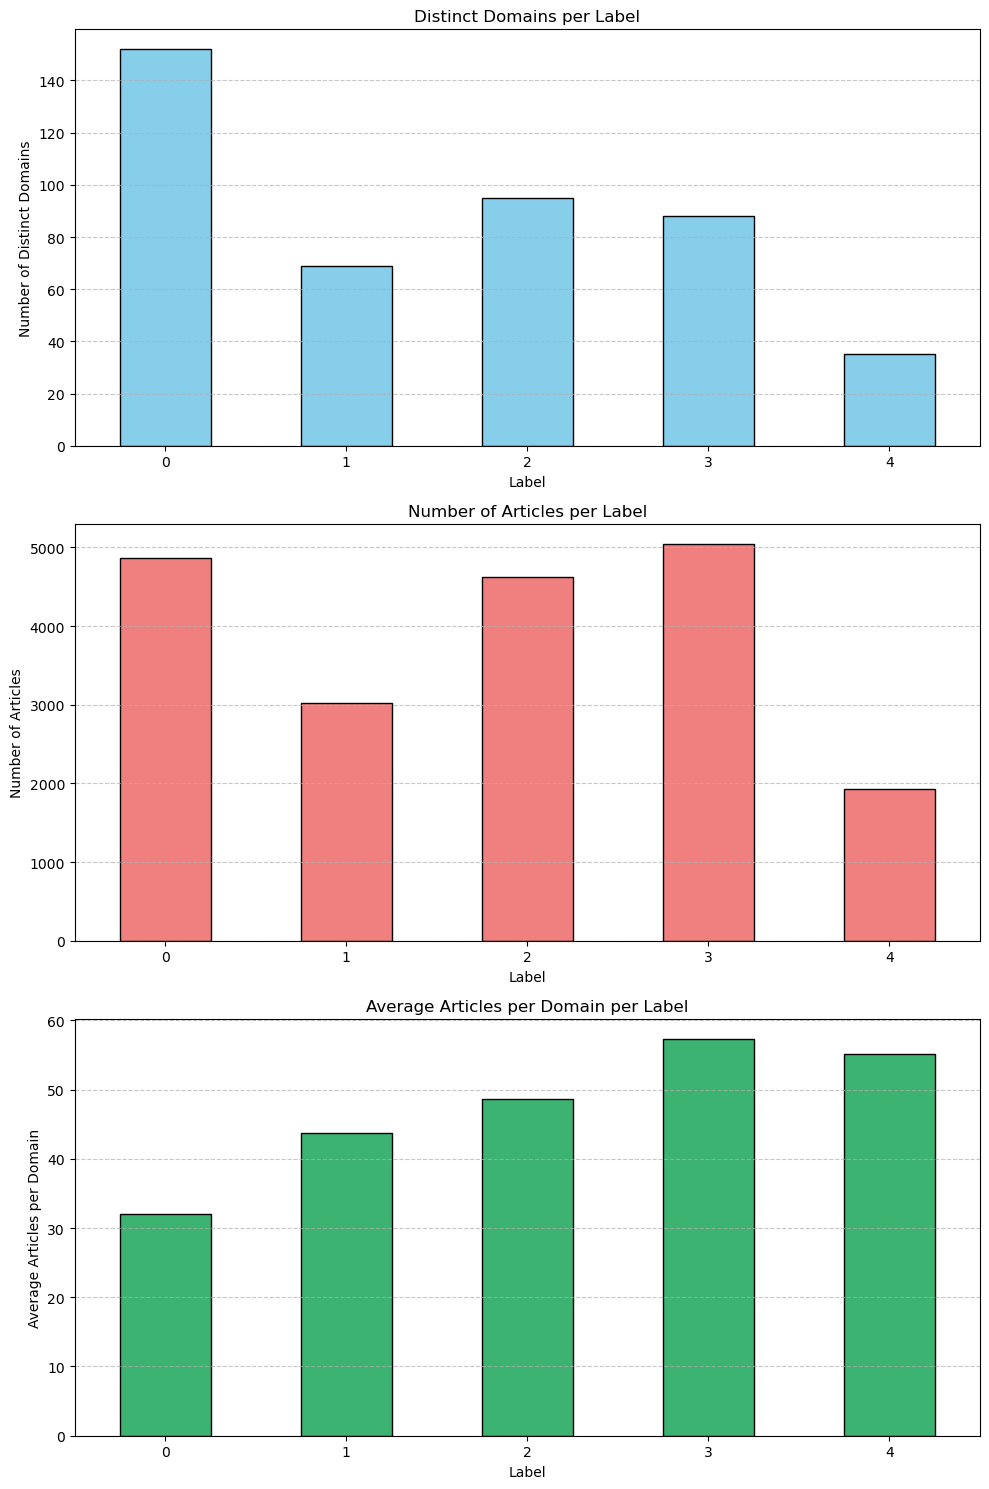

In [19]:
plot_label_analysis(df) 

In [20]:
df = df.reset_index(drop=True)
df.to_csv('Dataset/CleannedDataset/newDataframeWithOldCleanedPoliticsVersion.csv', index=False)